# Geographic Performance Analysis

In [1]:
import sys
sys.path.insert(0, '..')

import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

df = pd.read_csv('../data/processed/dataset.csv', parse_dates=['order_date', 'shipping_date'])

df = df.drop_duplicates('order_id', ignore_index=True)

In [2]:
sns.set_theme()

from scripts import visualization_config

## Which regions experience the highest delivery delay rates?

For this question I took only the orders that had delays. Orders that were delivered on time (or in advance) are not in the calculation.

In [3]:
delivery_delay = df['days_for_shipping_real'] - df['days_for_shipment_scheduled']
delayed_shipments = df[delivery_delay > 0]

delayed_shipments['late_days'] = delayed_shipments['days_for_shipping_real'] - delayed_shipments['days_for_shipment_scheduled']

order_regions_average_delays = (
    delayed_shipments
    .groupby('order_region')['late_days']
    .agg(['mean', 'count'])
    .sort_values(by='mean',ascending=False)
)

for mode, row in order_regions_average_delays.iterrows():
    print(f"{mode}: {np.around(row['mean'], 2)} days ({int(row['count'])} values)")

Central Asia: 1.74 days (102 values)
South of  USA: 1.65 days (753 values)
Canada: 1.64 days (153 values)
South Asia: 1.64 days (1865 values)
Eastern Asia: 1.63 days (1818 values)
Eastern Europe: 1.63 days (723 values)
West Africa: 1.63 days (626 values)
Western Europe: 1.63 days (5585 values)
Northern Europe: 1.63 days (1996 values)
West of USA: 1.62 days (1451 values)
Southeast Asia: 1.62 days (2421 values)
Caribbean: 1.62 days (1487 values)
South America: 1.62 days (2696 values)
Central America: 1.61 days (5156 values)
East of USA: 1.61 days (1276 values)
Oceania: 1.61 days (2382 values)
Central Africa: 1.61 days (320 values)
North Africa: 1.6 days (578 values)
West Asia: 1.6 days (1132 values)
Southern Europe: 1.59 days (1895 values)
East Africa: 1.59 days (348 values)
US Center: 1.58 days (1071 values)
Southern Africa: 1.53 days (214 values)


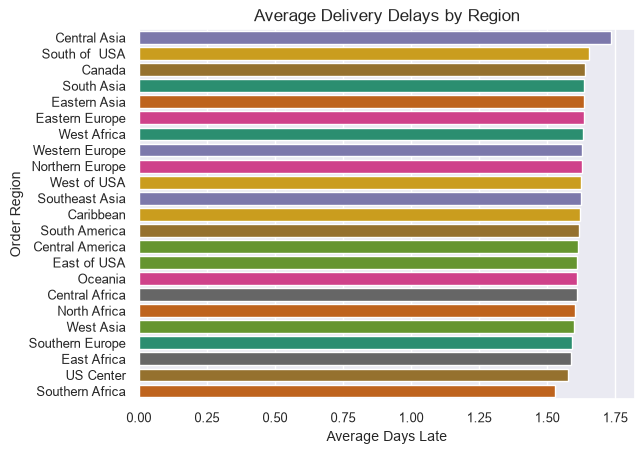

In [4]:
sns.barplot(data=delayed_shipments, x='late_days', y='order_region', hue='order_region', order=order_regions_average_delays.index, errorbar=None, legend=False, palette='Dark2')

plt.title('Average Delivery Delays by Region')
plt.xlabel('Average Days Late')
plt.ylabel('Order Region')

plt.savefig('../visualizations/average-delivery-delays-by-region.png', bbox_inches='tight')
plt.show()

There are 23 order regions in the dataset, and the variability is low in delivery delay rates. Central Asia experiences the highest average delivery delays - 1.74 days - and Southern Africa the least - 1.53 days.

It's worth noting though that these regions have among the lowest orders in general, so the values might be noise. 

- Central Asia has 102 orders
- Southern Africa has 214 orders

## Are there geographical markets with consistently longer shipping times?

## Are high-volume markets also experiencing poor shipping performance?

## Which geographical areas should management prioritize?